# Week 10 Class Demo 1: Logistic Regression with Healthcare Cost Classification

## Business Scenario
A healthcare benefits team wants to identify records likely to fall into the **higher-cost half of the dataset** so analysts can prioritize review and investigate cost patterns. This is a teaching example, not a diagnosis or eligibility decision.

We will use the supplied `ClassDemo_health_data.csv`. Because `health_cost` is continuous, we create a binary `high_cost` target for classification.

## Learning Objectives
By the end of this class, students will be able to:
1. Distinguish regression from classification.
2. Convert a continuous business outcome into a transparent binary target.
3. Explain each major line in a logistic-regression workflow and adapt it to another business case.
4. Prevent target leakage and identifier misuse.
5. Interpret probabilities, thresholds, coefficients, odds ratios, confusion matrices, and classification metrics.
6. Translate technical output into a BBA recommendation.
7. Identify which parts of the code must change when the dataset, target, or business objective changes.

## Week 10 Learning Resources

- [Course Delivery Plan](https://lms.nait.ca/d2l/common/dialogs/quickLink/quickLink.d2l?ou=182241&type=content&rcode=42c15f8c0a8a487a9c578486-56)
- **Lecture 17:** [Recording](https://nait.video.yuja.com/V/Video?v=1347382&node=7565679&a=896556665) | [Presentation](https://lms.nait.ca/d2l/common/dialogs/quickLink/quickLink.d2l?ou=182241&type=content&rcode=EE964922-8905-4C5B-ACC8-340F77B2A0B1-551455) | [Notebook](https://nbviewer.org/github/Dong2Yo/PredcitiveAnalysis_BusinessProfessional/blob/main/lectures/Lecture17_beginning_classification_part_1.ipynb)
- [Lecture 17–18 workbook](https://github.com/Dong2Yo/PredcitiveAnalysis_BusinessProfessional/blob/main/workbooks/Lecture17_18_Workbook.ipynb) | [Solution](https://colab.research.google.com/drive/1Wu6uNhSpgrU-ClN4um3nqw8IDCNldbdT?usp=sharing)
- [*Machine Learning with Python for Everyone*](https://learning.oreilly.com/library/view/machine-learning-with/9780134845708/): Chapter 3, Chapter 5, and Chapter 6 through the NAIT O’Reilly subscription.


## How to Use This Notebook to Learn Transferable Code

Do not treat the code as a recipe to memorize. For every block, ask four questions:

1. **What business problem is this block solving?**
2. **Which parts are reusable in another dataset?**
3. **Which names or assumptions would I need to change?**
4. **How would I explain the output to a manager?**

The recurring pattern is:

**Define the decision → inspect data → define target `y` → define predictors `X` → split data → preprocess → fit → predict → evaluate → recommend.**

### Replication mindset
In another business case, the Python functions may stay almost identical while the meaning changes. For example:
- banking: predict `loan_default`;
- marketing: predict `customer_churn`;
- retail: predict `repeat_purchase`;
- operations: predict `late_delivery`;
- HR analytics: predict a non-sensitive operational outcome such as `training_completion`.

The analyst's most important job is to define the target and error costs correctly before fitting a model.

## Regression vs. Classification: What Are We Trying to Predict?

Before building a classification model, it is important to understand the difference between **regression** and **classification**.

Both are **supervised machine learning** methods.

In supervised learning, we have:

- **Predictors (`X`)**: information we use to make a prediction
- **Target (`y`)**: the outcome we want to predict

The major difference between regression and classification is the **type of target we want to predict**.

---

### Regression Predicts a Number

Use **regression** when the target is a **continuous numerical value**.

Examples include:

- predicting annual sales revenue
- predicting house prices
- predicting monthly customer spending
- predicting delivery time
- predicting healthcare cost

For example, suppose we want to predict:

```text
health_cost = $4,850

## Classification Predicts a Category

Use **classification** when the target represents a **category or class** rather than a continuous numerical value.

Examples include:

- predicting whether a customer will **churn or stay**
- predicting whether a loan will **default or not default**
- predicting whether a transaction is **fraudulent or legitimate**
- predicting whether a delivery will be **late or on time**
- predicting whether a healthcare record belongs to a **higher-cost or lower-cost category**

The key question changes from:

> **"How much?"**

to:

> **"Which category?"**

---

### Let's Use the Same Healthcare Example

Previously, we considered predicting the actual healthcare cost:


 - health_cost = $4,850

Now we can predict the healthcare cost category:


- 0 = Lower-cost category
- 1 = Higher-cost category

## 1. Import the Libraries

### Why this step exists
Python libraries provide tested implementations of common data and machine-learning operations. Importing them at the top makes the dependencies visible.

### What each import is for
- `numpy`: numerical calculations and arrays.
- `pandas`: loading and manipulating tabular data.
- `matplotlib.pyplot`: charts.
- `train_test_split`: creates separate datasets for model development and evaluation.
- `StandardScaler`: standardizes predictors.
- `Pipeline`: chains preprocessing and a model into one object.
- `LogisticRegression`: the classifier used in this demo.
- functions from `sklearn.metrics`: evaluate predictions.

### What students would change in another case
Usually very little. If you choose a different algorithm or metric, add or replace that import. The dataset filename and column names come later.

In [50]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, classification_report, roc_auc_score, RocCurveDisplay
RANDOM_STATE=42
pd.set_option("display.max_columns",30)
print("Libraries loaded.")

Libraries loaded.


### Student Check-in

Why is it useful to keep imports together near the beginning of a notebook?

<details>
<summary><strong>Reveal suggested answer</strong></summary>

It makes the notebook dependencies easy to see and reproduce. When adapting the analysis, students can quickly identify which libraries and modeling tools are required.

</details>

## 2. Load the Healthcare Dataset

`pd.read_csv(DATA_FILE)` converts the CSV into a pandas **DataFrame**, a table with rows and named columns.

The next three commands answer immediate sanity-check questions:
- `len(df)` → how many records were loaded?
- `df.shape[1]` → how many columns?
- `df.head()` → do the first rows look structurally reasonable?
- `df.dtypes` → did numeric columns load as numbers and categories as text?

### Generalize this code
For another CSV, change `DATA_FILE`. If column names differ, later code must use those new names. Always inspect the loaded result before modeling. A model cannot repair a mistakenly loaded or misunderstood dataset.

In [53]:
DATA_FILE = "ClassDemo_health_data.csv"
df = pd.read_csv(DATA_FILE)
print(f"Rows: {len(df):,}; columns: {df.shape[1]}")
display(df.head())
print(df.dtypes)

Rows: 65,000; columns: 11


,patient_id,age,bmi,systolic_bp,diastolic_bp,resting_hr,exercise_hours,sleep_hours,smoker,cholesterol,health_cost
0,P000001,51,23.1,118,68,75,2.1,7.6,No,211,6288
1,P000002,31,19.5,88,75,78,6.9,6.6,No,141,4930
2,P000003,22,24.2,112,67,74,2.2,5.9,No,185,4877
3,P000004,23,31.1,88,57,82,4.1,7.7,No,144,5148
4,P000005,49,31.3,132,60,66,4.1,7.4,Yes,217,6505


patient_id         object
age                 int64
bmi               float64
systolic_bp         int64
diastolic_bp        int64
resting_hr          int64
exercise_hours    float64
sleep_hours       float64
smoker             object
cholesterol         int64
health_cost         int64
dtype: object


### Understand the Variables Before Modeling

The dataset contains an identifier (`patient_id`), health-related predictors, a text category (`smoker`), and continuous `health_cost`.

At this point, **do not start modeling yet**. First decide which column represents the outcome. The original `health_cost` is numeric and continuous. Predicting it directly would be a **regression** problem. Because this week focuses on classification, we will create a class label.

### Student Check-in

If a retail dataset contains continuous `annual_spend`, what would predicting the exact dollar amount be? What could make it classification?

<details>
<summary><strong>Reveal suggested answer</strong></summary>

Predicting the exact amount is regression. It becomes classification if the business defines categories, for example `high_spend = 1` when annual spend exceeds a justified threshold.

</details>

## 3. Audit Data Quality

Before machine learning, verify the data you intend to model. The code below checks:

- descriptive statistics: do ranges look plausible for the dataset?
- missing values: does a column require a missing-data strategy?
- duplicate rows: are some records repeated?
- category values: are labels such as `Yes` and `No` consistent?

### Why it matters when replicating
Never copy preprocessing assumptions blindly. A customer dataset might contain `Yes`, `No`, and `Unknown`; a sales dataset might have missing prices; a logistics dataset might contain duplicate shipment records. Inspect first, then decide how to prepare.

In [57]:
display(df.describe(include="all").T)
print("Missing values:")
display(df.isna().sum().to_frame("missing"))
print("Duplicate rows:",df.duplicated().sum())
print("Smoker values:",df["smoker"].value_counts().to_dict())

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
patient_id,65000,65000,P000001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,65000.0,NaN,NaN,NaN,49.237646,18.191123,18.0,34.0,49.0,65.0,80.0
bmi,65000.0,NaN,NaN,NaN,27.535666,5.128453,16.5,24.0,27.5,31.0,46.0
systolic_bp,65000.0,NaN,NaN,NaN,114.747585,13.05679,88.0,105.0,115.0,124.0,168.0
diastolic_bp,65000.0,NaN,NaN,NaN,69.838446,7.974641,52.0,64.0,70.0,75.0,103.0
resting_hr,65000.0,NaN,NaN,NaN,75.613369,7.861584,45.0,70.0,76.0,81.0,107.0
exercise_hours,65000.0,NaN,NaN,NaN,2.978697,2.090964,0.0,1.4,2.5,4.0,12.0
sleep_hours,65000.0,NaN,NaN,NaN,7.005603,1.05064,3.5,6.3,7.0,7.7,10.0
smoker,65000,2,No,53151,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cholesterol,65000.0,NaN,NaN,NaN,180.091631,32.365393,105.0,158.0,180.0,202.0,312.0


Missing values:


,missing
patient_id,0
age,0
bmi,0
systolic_bp,0
diastolic_bp,0
resting_hr,0
exercise_hours,0
sleep_hours,0
smoker,0
cholesterol,0


Duplicate rows: 0
Smoker values: {'No': 53151, 'Yes': 11849}


## 4. Create the Classification Target

### Step 4.1: Choose a business definition
A classifier needs categories. We define:
- `high_cost = 0`: cost below the dataset median;
- `high_cost = 1`: cost at or above the dataset median.

### Step 4.2: Understand the code
`df["health_cost"].median()` calculates the middle cost value.

`df["health_cost"] >= COST_THRESHOLD` produces `True` or `False` for every row.

`.astype(int)` converts `False → 0` and `True → 1`.

### Step 4.3: Why display class counts?
`value_counts()` verifies that the target was created as expected. `normalize=True` displays proportions rather than raw counts.

### Replicate in another business case
The pattern is:
```python
threshold = df["continuous_measure"].median()
df["target"] = (df["continuous_measure"] >= threshold).astype(int)
```
But **do not automatically use a median in real projects**. A bank, retailer, or operations team may already have an established business threshold. The threshold should match the decision being supported.

In [59]:
COST_THRESHOLD = df["health_cost"].median()
df["high_cost"] = (df["health_cost"] >= COST_THRESHOLD).astype(int)
print(f"Dataset median health cost: ${COST_THRESHOLD:,.0f}")
display(df["high_cost"].value_counts().rename(index={0:"Below median",1:"At/above median"}).to_frame("records"))
display(df["high_cost"].value_counts(normalize=True).rename("proportion").to_frame())

Dataset median health cost: $6,327


,records
high_cost,
At/above median,32522
Below median,32478


,proportion
high_cost,
1,0.500338
0,0.499662


### Student Check-in

Why is target construction part of business analysis rather than just coding?

<details>
<summary><strong>Reveal suggested answer</strong></summary>

Because the rule determines what class 1 actually means. Changing the threshold changes which records count as positive and therefore changes the prediction problem, metrics, and decisions.

</details>

## 5. Build `X` and `y` and Prevent Leakage

Machine-learning examples commonly use two names:
- `X`: predictor matrix, the information available to the model;
- `y`: target vector, the answer we want the model to learn to predict.

### Why remove `health_cost`?
`high_cost` was created directly from `health_cost`. If `health_cost` remained in `X`, the model could reconstruct the answer. That is **target leakage**. Leakage can generate excellent-looking performance that does not represent a real predictive task.

### Why remove `patient_id`?
An identifier distinguishes records but is not intended to describe the phenomenon being modeled. IDs often contain no transferable business signal and can encourage accidental memorization.

### Why map `smoker` to 0/1?
The estimator expects numeric features. For a two-category field, mapping `No → 0`, `Yes → 1` is simple. For multiple unordered categories, use an encoding method such as one-hot encoding instead of arbitrary 1/2/3 labels.

### Replication rule
When working with another dataset, explicitly identify:
1. the target;
2. columns that reveal the target;
3. pure identifiers;
4. categorical fields requiring encoding;
5. variables that would not be available when the prediction must be made.

In [62]:
model_df=df.drop(columns=["patient_id","health_cost"]).copy()
model_df["smoker"] = model_df["smoker"].map({"No":0,"Yes":1})
X=model_df.drop(columns="high_cost")
y=model_df["high_cost"]
print("Predictors:",list(X.columns))
display(X.head())

Predictors: ['age', 'bmi', 'systolic_bp', 'diastolic_bp', 'resting_hr', 'exercise_hours', 'sleep_hours', 'smoker', 'cholesterol']


,age,bmi,systolic_bp,diastolic_bp,resting_hr,exercise_hours,sleep_hours,smoker,cholesterol
0,51,23.1,118,68,75,2.1,7.6,0,211
1,31,19.5,88,75,78,6.9,6.6,0,141
2,22,24.2,112,67,74,2.2,5.9,0,185
3,23,31.1,88,57,82,4.1,7.7,0,144
4,49,31.3,132,60,66,4.1,7.4,1,217


### Student Check-in

A churn dataset contains `cancellation_date` and the target is `churned`. Why could `cancellation_date` be leakage for a model intended to predict churn one month earlier?

<details>
<summary><strong>Reveal suggested answer</strong></summary>

Because the eventual cancellation date would not yet be known at the prediction time. It reveals future information about the target.

</details>

## 6. Split Training and Test Data

### Why not evaluate on the training data?
The model has already used the training observations to estimate its parameters. Evaluating on those same rows answers “How well does the model reproduce data it has seen?” We instead want “How well does the model generalize to unseen records?”

`train_test_split` creates two partitions. Here, `test_size=.25` reserves 25% for testing.

`stratify=y` keeps the class proportions similar in training and test data. This is especially helpful in classification.

`random_state=42` makes the random split reproducible. The number 42 is not mathematically special; consistency is the purpose.

### Why use a pipeline?
The pipeline performs scaling and logistic regression in sequence. When `.fit()` is called on the training data, the scaler learns only from training data and the model then learns from the transformed training data. This reduces preprocessing leakage and packages the workflow for later prediction.

In [65]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.25,random_state=RANDOM_STATE,stratify=y)
log_model=Pipeline([("scaler",StandardScaler()),("model",LogisticRegression(max_iter=1000,random_state=RANDOM_STATE))])
log_model.fit(X_train,y_train)
prob=log_model.predict_proba(X_test)[:,1]
pred=(prob>=.50).astype(int)
print(X_train.shape,X_test.shape)

(48750, 9) (16250, 9)


### Read the Fit-and-Predict Code Line by Line

`log_model.fit(X_train, y_train)` means: **learn preprocessing values and logistic-regression parameters from the training records and their known classes.**

`predict_proba(X_test)` returns probabilities for both classes. `[:, 1]` selects the probability of class 1, `high_cost = 1`.

`(prob >= .50).astype(int)` converts probability into a class at a 0.50 threshold. Importantly, **model fitting and threshold selection are different decisions**.

### Transfer to another case
If `y=1` means churn, fraud review, late delivery, or repeat purchase, the same code structure works. What changes is the meaning of class 1 and the business interpretation of errors.

### Student Check-in

What is the difference between `predict_proba()` and a class prediction?

<details>
<summary><strong>Reveal suggested answer</strong></summary>

`predict_proba()` provides estimated class probabilities. A class prediction applies a decision rule, such as probability >= 0.50, to choose a category.

</details>

## 7. Understand Logistic Regression Conceptually

### Why Do We Need Logistic Regression?

In **linear regression**, we predict a continuous number, such as:

- sales revenue
- healthcare cost
- delivery time

In **classification**, however, we want to predict a **category**.

In this healthcare example:

- `high_cost = 0` means the healthcare cost is below the defined threshold.
- `high_cost = 1` means the healthcare cost is at or above the defined threshold.

The goal of logistic regression is therefore to estimate:

> **How likely is this observation to belong to Class 1?**

---

### Step 1: Calculate a Linear Score

Logistic regression begins by combining the predictor variables into a linear equation:

$$
z = b_0 + b_1x_1 + b_2x_2 + \cdots + b_px_p
$$

Where:

- $z$ = the calculated linear score
- $b_0$ = the intercept
- $b_1, b_2, \ldots, b_p$ = coefficients learned by the model
- $x_1, x_2, \ldots, x_p$ = predictor values

For our healthcare dataset, we can think about the equation conceptually as:

$$
z = b_0
+ b_1(\text{age})
+ b_2(\text{BMI})
+ b_3(\text{systolic BP})
+ \cdots
+ b_p(\text{cholesterol})
$$

The actual coefficients are learned from the **training data** when we run:

```python
log_model.fit(X_train, y_train)

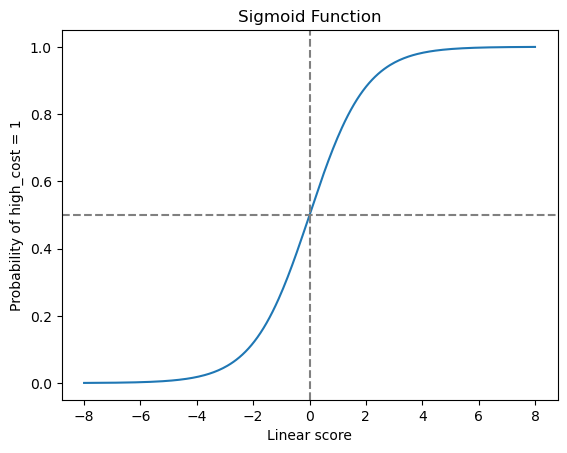

In [69]:
z=np.linspace(-8,8,300)
plt.plot(z,1/(1+np.exp(-z)))
plt.axhline(.5,color="gray",linestyle="--"); plt.axvline(0,color="gray",linestyle="--")
plt.xlabel("Linear score"); plt.ylabel("Probability of high_cost = 1"); plt.title("Sigmoid Function"); plt.show()

### How to Read the Sigmoid Plot
The curve shows that probability changes smoothly. A case predicted at 0.49 and a case predicted at 0.51 are very similar in estimated probability even though a 0.50 threshold assigns different classes. Business users should not confuse a hard class label with certainty.

### Student Check-in

Why might a manager prefer probabilities to only 0/1 labels?

<details>
<summary><strong>Reveal suggested answer</strong></summary>

Probabilities preserve risk ranking and uncertainty. They let the organization create thresholds or tiers that match capacity and the cost of different errors.

</details>

## 8. Evaluate the Classifier

### First understand the four possible outcomes
- **True Positive (TP):** predicted high cost, actually high cost.
- **False Positive (FP):** predicted high cost, actually below the defined threshold.
- **False Negative (FN):** predicted below threshold, actually high cost.
- **True Negative (TN):** predicted below threshold, actually below threshold.

### Metrics built from these outcomes
**Accuracy** asks: “What proportion of all predictions were correct?”

**Precision** asks: “Among records we flagged as class 1, what proportion really were class 1?” High precision matters when false alarms consume scarce resources.

**Recall** asks: “Among all actual class-1 records, what proportion did we find?” High recall matters when missing positive cases is costly.

**F1** combines precision and recall. It is useful when both error types matter and one summary measure is needed.

**ROC AUC** evaluates how well probability scores rank positive records above negative records across thresholds.

### General business principle
Never select a metric merely because it is common. Select metrics based on the business consequence of FP and FN.

In [73]:
def metric_table(y_true,pred,prob):
    return pd.Series({"accuracy":accuracy_score(y_true,pred),"precision":precision_score(y_true,pred,zero_division=0),"recall":recall_score(y_true,pred,zero_division=0),"f1":f1_score(y_true,pred,zero_division=0),"roc_auc":roc_auc_score(y_true,prob)}).round(3).to_frame("score")

,score
accuracy,0.794
precision,0.795
recall,0.791
f1,0.793
roc_auc,0.878


              precision    recall  f1-score   support

           0      0.792     0.796     0.794      8120
           1      0.795     0.791     0.793      8130

    accuracy                          0.794     16250
   macro avg      0.794     0.794     0.794     16250
weighted avg      0.794     0.794     0.794     16250



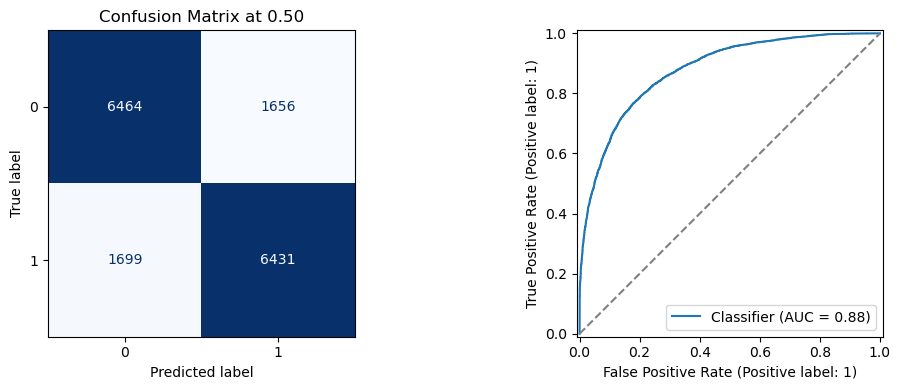

In [74]:
display(metric_table(y_test,pred,prob))
print(classification_report(y_test,pred,digits=3))
fig,axes=plt.subplots(1,2,figsize=(11,4))
ConfusionMatrixDisplay.from_predictions(y_test,pred,ax=axes[0],cmap="Blues",colorbar=False)
axes[0].set_title("Confusion Matrix at 0.50")
RocCurveDisplay.from_predictions(y_test,prob,ax=axes[1]); axes[1].plot([0,1],[0,1],"--",color="gray")
plt.tight_layout(); plt.show()

### Student Check-in

In a late-delivery model, suppose missing a truly late shipment is more costly than unnecessarily reviewing an on-time shipment. Which metric may deserve greater emphasis?

<details>
<summary><strong>Reveal suggested answer</strong></summary>

Recall of the late-delivery class, because it measures how many actual late shipments were detected. Precision should still be reported to quantify unnecessary reviews.

</details>

## 9. Interpret Logistic Regression Coefficients

The coefficient sign indicates the direction of association with the modeled log-odds, holding the other included predictors constant. Because this pipeline standardizes predictors, coefficients refer to a one-standard-deviation increase in each predictor.

Exponentiating a coefficient gives an **odds ratio**:
- odds ratio > 1: associated with higher modeled odds of class 1;
- odds ratio < 1: associated with lower modeled odds;
- odds ratio around 1: relatively little change in odds for that standardized increase.

### Critical interpretation rule
A predictive coefficient does **not** prove causation. “Associated with higher predicted odds” is safer than “causes higher cost.”

In [77]:
coef=pd.Series(log_model.named_steps["model"].coef_[0],index=X.columns)
coef_table=pd.DataFrame({"standardized_coefficient":coef,"odds_ratio":np.exp(coef)}).sort_values("odds_ratio",ascending=False)
display(coef_table.round(3))

,standardized_coefficient,odds_ratio
age,1.216,3.374
bmi,1.191,3.289
smoker,1.086,2.961
systolic_bp,0.202,1.224
diastolic_bp,-0.005,0.995
cholesterol,-0.010,0.990
resting_hr,-0.010,0.990
sleep_hours,-0.155,0.856
exercise_hours,-0.362,0.697


### Student Check-in

What wording is safer than saying a positive model coefficient “causes” the outcome?

<details>
<summary><strong>Reveal suggested answer</strong></summary>

Say that higher values of the predictor are associated with higher modeled odds of class 1, holding the other included predictors constant.

</details>

## 10. Thresholds Turn Predictions into Operations

A 0.50 threshold is not automatically the best operational rule. Imagine an analysis team that can review only 20% of records. One option is to rank records by predicted probability and select approximately the top 20%.

The code below uses `np.quantile` to find the probability cut point corresponding to the available capacity.

### Transferable pattern
This idea applies to marketing call lists, collections review, retention outreach, fraud investigation queues, and quality-control inspections. Whenever capacity is limited, ask whether a fixed probability threshold or a ranked capacity rule better matches the decision.

In [80]:
capacity_share=.20
capacity_threshold=np.quantile(prob,1-capacity_share)
capacity_pred=(prob>=capacity_threshold).astype(int)
print(f"Threshold for top {capacity_share:.0%}: {capacity_threshold:.3f}")
display(metric_table(y_test,capacity_pred,prob))
print("Records flagged:",capacity_pred.sum())

Threshold for top 20%: 0.868


,score
accuracy,0.678
precision,0.945
recall,0.378
f1,0.540
roc_auc,0.878


Records flagged: 3250


### Student Check-in

If review capacity increases from 20% to 30%, what part of this example would you change? What trade-off would you expect?

<details>
<summary><strong>Reveal suggested answer</strong></summary>

Change `capacity_share` to `.30`. More records would be flagged. Recall would often increase because more positive cases can be captured, while precision may decrease because more lower-ranked records are included.

</details>

## 11. Replication Template for Another Business Case

When adapting this notebook, use this checklist:

### A. Rewrite the business question
Example: “Which customers are likely to churn in the next 90 days?”

### B. Redefine the target
Set `y` to an existing binary field or transparently construct one from a justified rule. Document what 0 and 1 mean.

### C. Rebuild predictors
Remove IDs, target-defining fields, post-outcome data, and information unavailable at prediction time. Encode categories appropriately.

### D. Reuse the technical skeleton
Split → pipeline → fit → probability → threshold → evaluation.

### E. Redefine errors in business language
What does FP mean in this business? What does FN mean? Which is more costly?

### F. Justify the decision rule
Do not automatically keep 0.50. Link the threshold to costs, capacity, regulations, or service objectives.

### G. Communicate limitations
Describe assumptions, data limitations, monitoring needs, and the difference between prediction and causation.

## 12. Student Transfer Challenge

Choose one business case: customer churn, late delivery, repeat purchase, loan repayment, or equipment failure. Without running code, identify:
1. a possible `y`;
2. three possible predictors;
3. one likely leakage variable;
4. what FP means;
5. what FN means;
6. whether precision or recall might deserve more emphasis;
7. which lines of this notebook would stay nearly unchanged.

### Student Check-in

Example answer for customer churn

<details>
<summary><strong>Reveal suggested answer</strong></summary>

`y` could be churn within a defined future period. Predictors might include tenure, service usage, and support-contact count measured before prediction. A cancellation date would be leakage if it is only known after churn. FP means flagging a customer who would stay; FN means missing a customer who leaves. The preferred metric depends on outreach cost versus the cost of missed churn. The train/test split, pipeline, fit, probability, and metric code can be reused after column names and preprocessing are adapted.

</details>

## Key Takeaways
- Start with the decision, not the algorithm.
- `X` contains information available for prediction; `y` contains the outcome.
- Remove leakage before trusting model performance.
- Logistic regression estimates class probabilities; a threshold converts probabilities into actions.
- Evaluate the types of errors that matter to the business.
- Replication means preserving the modeling logic while redefining the target, predictors, error interpretation, and decision rule for the new business context.